### this script calculate the similarity between the domestic paper and internationally funded and internationally not-funded to investigate whether funding makes paper more similar

In [1]:
import pandas as pd
import numpy as np
import time
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial import distance
from tqdm import tqdm 
from multiprocessing import Pool, cpu_count
import random

### load embeddings

In [2]:
embedding_path = "/gpfs/slate-sciencegenome/Embeddings/Data/wos_embedding_specter_all.npz"
embedding_file = np.load(embedding_path)
embeddings = embedding_file['emb']
uids = embedding_file['uids']

### load the file contains all the publications

In [3]:
pub_all_path = "../../data/dropbox/LaborDivision/data/deriveddata/all/pub_author.csv"
pub_all = pd.read_csv(pub_all_path)
pub_all = pub_all.drop(columns=['seqno','lastname','num_author'])

### load uids of all the publications

In [4]:
uid_path = "../../data/dropbox/LaborDivision/data/cleanedraw/ostbk_uid.pkl"
uid_df = pd.read_pickle(uid_path)

In [5]:
pub_all['ost_bk'] = pub_all['ost_bk'].astype('str')
pub_all['uid'] = pub_all['ost_bk'].map(uid_df)

### load funding data

In [6]:
pub_funding_path = "../../data/dropbox/LaborDivision/data/deriveddata/all/pub_funding.pkl"
pub_funding = pd.read_pickle(pub_funding_path)
pub_funding.head(2)

,ost_bk,funders
0,29768167,[GBR]
1,29768198,[IRN]


In [7]:
pub_funding['ost_bk'] = pub_funding['ost_bk'].astype('str')

In [10]:
pub_all.head()

,ost_bk,cluster_id,cntry,role,year,dis,title,alpha,intl,uid
0,29768068,40806321.0,CAN,F,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
1,29768068,41639269.0,CAN,M,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
2,29768068,53722752.0,CAN,L,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
3,29768070,65683243.0,JPN,F,2008,51,Biphasic effects of orexin-A on autonomic nerv...,noalp,1,WOS:000260516300012
4,29768070,79129017.0,JPN,M,2008,51,Biphasic effects of orexin-A on autonomic nerv...,noalp,1,WOS:000260516300012


### create an dict which records uid and the index in uids array to derive the embedding from the embedding array

In [44]:
uid_index_dict={}
n = 0
for uid in tqdm(uids):
    uid_index_dict[uid]=n
    n=n+1

100%|███████████████████████████| 84162157/84162157 [01:38<00:00, 852574.35it/s]


### select domestic publications

In [14]:
pub_dome = pub_all[pub_all.intl==0][['cntry','dis','uid']].drop_duplicates()
pub_dome['type']='dome'

In [30]:
pub_dome.head(2)

,cntry,dis,uid,type
0,CAN,56,WOS:000259648000022,dome
8,RUS,27,WOS:000261972700004,dome


### select international publications

In [12]:
pub_intl = pub_all[pub_all.intl==1][['cntry','dis','uid','ost_bk']].drop_duplicates()

In [13]:
#add funding data into international publications
pub_intl = pub_intl.merge(pub_funding, on='ost_bk', how='left')
pub_intl['funders'] = pub_intl['funders'].fillna('not-funded')

In [26]:
def assign_type(authorcntry, fundcntrys):
    if fundcntrys in ['not-funded','incomplete']:
        return fundcntrys
    elif authorcntry in fundcntrys:
        return 'self'
    else:
        return 'other'
pub_intl['type'] = pub_intl.apply(lambda x: assign_type(x.cntry, x.funders), axis=1)

In [27]:
# measure the proportion of papers that have "incomplete" funding information
len(pub_intl[pub_intl.funders=='incomplete']['ost_bk'].unique())/len(pub_intl[pub_intl.funders!='not-funded']['ost_bk'].unique())

0.48659219596608805

In [31]:
pub_intl.head(2)

,cntry,dis,uid,ost_bk,funders,type
0,JPN,51,WOS:000260516300012,29768070,not-funded,not-funded
1,CHN,51,WOS:000260516300012,29768070,not-funded,not-funded


In [34]:
pub_filter = pd.concat([pub_dome, pub_intl.drop(columns=['funders','ost_bk'])])
pub_filter.head(2)

,cntry,dis,uid,type
0,CAN,56,WOS:000259648000022,dome
8,RUS,27,WOS:000261972700004,dome


In [39]:
cntry_dis_dict = {}
cntry_dis_arrays = pub_filter[['cntry','dis','type','uid']].values
for row in tqdm(cntry_dis_arrays):
    cntry = row[0]
    dis = row[1]
    type = row[2]
    uid = row[3]
    
    # Check if the key_A already exists in the nested dictionary
    if (cntry,dis) in cntry_dis_dict:
        # Check if the key_B already exists for the key_A
        if type in cntry_dis_dict[(cntry,dis)]:
            # Append the value_C to the existing list
            cntry_dis_dict[(cntry,dis)][type].append(uid)
        else:
            # Create a new key_B entry with a list containing value_C
            cntry_dis_dict[(cntry,dis)][type] = [uid]
    else:
        # Create a new key_A entry with a nested dictionary containing key_B and value_C
        cntry_dis_dict[(cntry,dis)] = {type: [uid]}

100%|███████████████████████████| 21863524/21863524 [00:32<00:00, 677655.37it/s]


In [40]:
def return_embeddings(pubs,uid_index_dict,embedding):
    embed_index = []
    for pub in pubs:
        if pub in uid_index_dict:
            embed_index.append(uid_index_dict[pub])
    if len(embed_index)>0:
        embed_mean = np.mean(embedding[embed_index], axis=0)
        return embed_mean
    else:
        return np.zeros(64)

In [42]:
pub_filter.type.unique()

array(['dome', 'not-funded', 'self', 'other', 'incomplete'], dtype=object)

In [46]:
cntry_dis_type_res=[]
for cntry_dis in tqdm(cntry_dis_dict.keys()):
    if 'dome' in cntry_dis_dict[cntry_dis]:
        pub_dome = cntry_dis_dict[cntry_dis]['dome']
        embed_dome = return_embeddings(pub_dome, uid_index_dict, embeddings)
        for t in ['not-funded','self','other']:
            if t in cntry_dis_dict[cntry_dis]:
                pub = cntry_dis_dict[cntry_dis][t]
                embed_pub = return_embeddings(pub, uid_index_dict, embeddings)
                if not np.all(embed_dome==0) and not np.all(embed_pub==0):
                    cosine_distance = 1-distance.cosine(embed_dome, embed_pub)
                    cntry_dis_type_res.append([cntry_dis[0], cntry_dis[1], t, cosine_distance])

100%|████████████████████████████████████| 21259/21259 [00:38<00:00, 559.15it/s]


In [47]:
cntry_dis_type = pd.DataFrame(cntry_dis_type_res, columns=['cntry','dis','type','similarity'])

In [48]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_group_meta.csv'
stgroup_df=pd.read_csv(stgroup_path)[['Code','ST']].drop_duplicates()
stgroup_df=stgroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
stgroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [49]:
cntry_dis_type = cntry_dis_type.merge(stgroup_df, left_on='cntry', right_on='Code')

In [50]:
cntry_dis_type.head()

,cntry,dis,type,similarity,Code,ST
0,CAN,56,not-funded,0.983991,CAN,Advanced
1,CAN,56,self,0.932642,CAN,Advanced
2,CAN,56,other,0.983963,CAN,Advanced
3,CAN,69,not-funded,0.977928,CAN,Advanced
4,CAN,69,self,0.998438,CAN,Advanced


In [56]:
cntry_type = cntry_dis_type.groupby(['cntry','ST','type'])['similarity'].mean().reset_index()

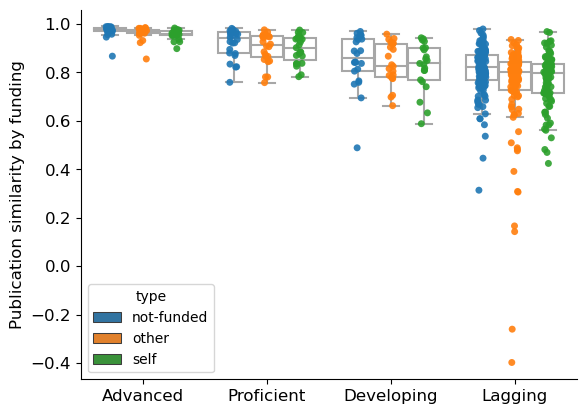

In [63]:
fig, ax=plt.subplots()
color={'L':'#7EB0CC','S':'#F27405'}
order = ['Advanced','Proficient','Developing','Lagging']
sns.stripplot(x='ST',y='similarity',data=cntry_type, hue='type', ax=ax, order=order,dodge=True, alpha=0.9, legend=False)
sns.boxplot(x='ST',y='similarity',data=cntry_type, hue='type',
            boxprops={'facecolor':'none', 'edgecolor':'#A7A7A7'},
            medianprops={'color':'#A7A7A7'},
            whiskerprops={'color':'#A7A7A7'},
            capprops={'color':'#A7A7A7'},
            order=order,
            fliersize=0,
            ax=ax)


ax.set_ylabel("Publication similarity by funding", fontsize=12)
ax.set_xlabel("")
ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.savefig('../../data/dropbox/LaborDivision/figs/pub_similarity_derived_by_funding.pdf',bbox_inches='tight')

In [60]:
cntry_type.groupby(['ST','type'])['similarity'].median()

ST          type      
Advanced    not-funded    0.977763
            other         0.970344
            self          0.958927
Developing  not-funded    0.859802
            other         0.828063
            self          0.836505
Lagging     not-funded    0.822298
            other         0.799941
            self          0.795765
Proficient  not-funded    0.939980
            other         0.912307
            self          0.901554
Name: similarity, dtype: float64

In [42]:
res = return_similarity(cntry_dis_dome,id_select_dome, embedding_select_dome, cntry_dis_intl,id_select_intl, embedding_select_intl)

100%|███████████████████████████████████| 16137/16137 [2:55:59<00:00,  1.53it/s]


In [43]:
pd.DataFrame(res, columns=['cntry','dis','similarity','type']).to_csv('res.csv',index=False)

In [25]:
res_df = pd.read_csv('res.csv')
res_df.head(2)

,cntry,dis,similarity,type
0,AFG,1,0.961312,not_fund
1,AFG,1,0.883921,other_fund


In [26]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_group_meta.csv'
stgroup_df=pd.read_csv(stgroup_path)[['Code','ST']].drop_duplicates()
stgroup_df=stgroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
stgroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [27]:
res_df = res_df.merge(stgroup_df, left_on='cntry', right_on='Code')

### examine the raw data without limiting the number of publications per discipline

In [31]:
raw_df = res_df.groupby(['cntry','ST','type'])['similarity'].mean().reset_index()

In [34]:
raw_df = raw_df.groupby(['ST','type'])['similarity'].mean().reset_index(name='similarity')
raw_df = raw_df.pivot(index='ST',columns='type',values='similarity')
raw_df

type,not_fund,other_fund,self_fund
ST,,,
Advanced,0.971240,0.961838,0.956413
Developing,0.848517,0.837468,0.822528
Lagging,0.808209,0.748483,0.770187
Proficient,0.918062,0.897704,0.894975


In [36]:
cnt_dome = pub_dome[['ost_bk','cntry','dis']].drop_duplicates().groupby(['cntry','dis']).size().reset_index(name='cnt_dome')

In [51]:
cnt_dome[(cnt_dome.cntry=='CHN')&(cnt_dome.dis==109)]

,cntry,dis,cnt_dome
2773,CHN,109,4


In [39]:
cnt_fund = intl_fund.drop_duplicates(subset=['ost_bk','cntry']).groupby(['cntry','dis','fund_type']).size()

In [42]:
cnt_fund = cnt_fund.reset_index(name='cnt').pivot(index=['cntry','dis'],columns='fund_type',values='cnt')

In [46]:
cnt_fund = cnt_fund.reset_index()

In [54]:
cnt_df = cnt_dome.merge(cnt_fund, on=['cntry','dis'])

### filter cntry-dis pairs by excluding nan values and excluding small publication volumes

In [57]:
cnt_df = cnt_df.dropna()

In [60]:
mask = (cnt_df['cnt_dome'] >= 10) & (cnt_df['not_fund'] >= 10) & (cnt_df['other_fund'] >= 10) & (cnt_df['self_fund'] >= 10)
cnt_df = cnt_df[mask]

In [65]:
cnt_df = cnt_df.melt(id_vars=['cntry','dis'], var_name='type',value_name='pubcnt')

In [67]:
cnt_df.type.unique()

array(['cnt_dome', 'not_fund', 'other_fund', 'self_fund'], dtype=object)

In [71]:
res_filter = res_df.merge(cnt_df, on=['cntry','dis','type'])

In [73]:
res_filter = res_filter.groupby(['cntry','ST','type'])['similarity'].mean().reset_index()
res_filter = res_filter.groupby(['ST','type'])['similarity'].mean()
res_filter = res_filter.reset_index().pivot(index='ST',columns='type',values='similarity')
res_filter

type,not_fund,other_fund,self_fund
ST,,,
Advanced,0.975709,0.975001,0.967709
Developing,0.955662,0.921168,0.934082
Lagging,0.965951,0.955912,0.937338
Proficient,0.960925,0.952470,0.945313


In [76]:
np.exp(0.166)

1.180573101723276

In [53]:
pub_all[(pub_all.cntry=='CHN')&(pub_all.dis==109)]

,ost_bk,cluster_id,cntry,role,year,dis,title,alpha,intl,uid,newid
1810534,31673747,79515432.0,CHN,F,2009,109,CGJung and China: A Continued Dialogue,single,0,WOS:000273360900001,415027
3390095,33547238,30231907.0,CHN,F,2010,109,Garden of the Heart-Soul in the Earthquake Are...,alpha,0,WOS:000277597300001,781434
3390096,33547238,79515575.0,CHN,L,2010,109,Garden of the Heart-Soul in the Earthquake Are...,alpha,0,WOS:000277597300001,781434
4679295,34875142,5227098.0,CHN,F,2010,109,German Psychoanalysts in China and the Start o...,single,0,WOS:000286781500007,1079227
18103567,49740502,46822535.0,CHN,F,2018,109,Societal Change and Language Change in China: ...,noalp,1,WOS:000429150500009,4010787
18103569,49740502,27097903.0,CHN,L,2018,109,Societal Change and Language Change in China: ...,noalp,1,WOS:000429150500009,4010787
26815948,58810901,5033694.0,CHN,F,2015,109,FACTORS AFFECTING THE UNDERSTANDING AND USE OF...,single,0,WOS:000358118500009,5945588
36053097,66922385,42565805.0,CHN,F,2020,109,The History of Psychoanalysis in China,alpha,1,WOS:000507608900002,7969542


In [53]:
meta = meta.merge(stgroup_df, left_on='cntry', right_on='Code')

In [55]:
meta.groupby(['ST']).agg({'other':'mean','not':'mean','self':'mean' })

,other,not,self
ST,,,
Advanced,0.961838,0.971240,0.956413
Developing,0.831751,0.865805,0.822528
Lagging,0.801957,0.825822,0.770187
Proficient,0.903805,0.924991,0.894975


In [77]:
cntry='KAZ'
dis=61
pub_dome[(pub_dome.cntry==cntry)&(pub_dome.dis==dis)].title.to_list()

['Express measurement of solid fuel ash content by nuclear gamma-method',
 'Increasing sensitivity of coal analysis by gamma-albedo method']

In [78]:
a = intl_fund[(intl_fund.cntry==cntry)&(intl_fund.dis==dis)&(intl_fund.fund_type=='self_fund')]
pub_all[pub_all.newid.isin(a.newid)].drop_duplicates(subset='ost_bk').title.to_list()

['Apoptotic and genotoxic effects of low-intensity ultrasound on healthy and leukemic human peripheral mononuclear blood cells']

In [79]:
a

,ost_bk,cntry,dis,newid,funders,fund_type
4080513,74325043,KAZ,61,9633206,[KAZ],self_fund


In [80]:
b = intl_fund[(intl_fund.cntry==cntry)&(intl_fund.dis==dis)&(intl_fund.fund_type=='notfunded')]
pub_all[pub_all.newid.isin(b.newid)].drop_duplicates(subset='ost_bk').title.to_list()

['Preparation of deuterium-labeled biotransformation products of 2,4,6-trinitrotoluene',
 'Iatrogenic Superficial External Pudendal Artery Pseudoaneurysm: Treatment with Doppler US-Guided Compression',
 'Flow Diversion with Low-Profile Braided Stents for the Treatment of Very Small or Uncoilable Intracranial Aneurysms at or Distal to the Circle of Willis',
 "In-vitro analysis of the dissolution kinetics and systemic availability of plutonium ingested in the form of 'hot' particles from the Semipalatinsk NTS",
 'Site-specific concentration of uranium in urine of workers of the hydrometallurgical plant of Stepnogorsk mining and chemical combine']

In [10]:
meta = not_df.merge(self_df, on=['cntry','dis'])

In [12]:
meta['diff'] = meta['self']-meta['not']

In [61]:
meta.sort_values(by='diff').head(10)

,cntry,dis,not,self,diff
2413,DZA,13,0.790140,-0.747440,-1.537580
3425,GEO,82,0.907764,-0.460649,-1.368413
9243,TZA,78,0.924263,-0.336185,-1.260449
6422,NGA,77,0.982090,-0.270477,-1.252566
1882,CUB,13,0.725042,-0.511660,-1.236702
1055,BRN,12,0.611757,-0.615773,-1.227530
716,BGD,13,0.902631,-0.303843,-1.206474
6367,NCL,19,0.797864,-0.363661,-1.161525
5398,LBN,13,0.866212,-0.276261,-1.142474
5062,KAZ,61,0.501015,-0.630304,-1.131320


<Axes: xlabel='not', ylabel='self'>

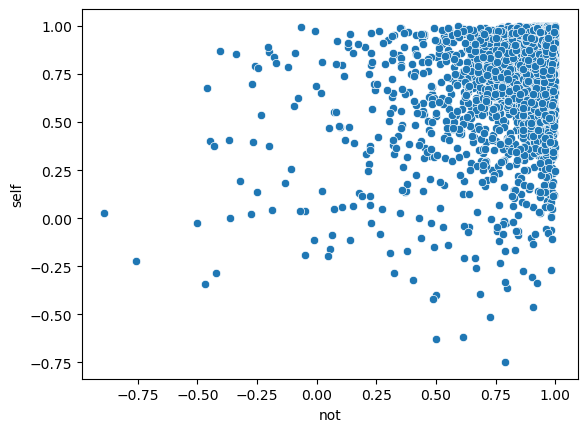

In [16]:
sns.scatterplot(x='not',y='self',data=meta)

In [5]:
self_df = self_df

,cntry,dis,similarity
0,AFG,111,0.992157
1,AFG,113,0.762848
2,AGO,18,0.990658
3,AGO,25,0.834230
4,AGO,38,0.930783
...,...,...,...
10022,ZWE,88,0.496954
10023,ZWE,96,-0.115899
10024,ZWE,113,0.882880
10025,ZWE,119,0.938946


In [4]:
not_df

,cntry,dis,similarity
0,AFG,1,0.961312
1,AFG,18,0.953006
2,AFG,38,0.453532
3,AFG,43,0.865263
4,AFG,44,0.955858
...,...,...,...
14943,ZWE,142,0.966515
14944,ZWE,143,0.921431
14945,ZWE,144,0.935544
14946,ZWE,145,0.933606
